# Session Variability

Within-session rear variability and its relationship to reward, at native 50 Hz DANNCE resolution.

- Rears are detected + maximally aligned to the session template in the validated 20 Hz (SLEAP-rate) domain (`clirb.events`), then the alignment anchor is mapped to the native ~50 Hz DANNCE stream via `dannce_idx_for_sleap_cams`.
- Each rear becomes a 4 s (+/-2s around the alignment anchor) trajectory in native-rate PC space and world-frame keypoint space (`clirb.native_dannce`).
- Rears whose +/-2s window would run off the session boundary are excluded entirely (not clipped) -- they get no variability value and do not enter any other rear's window.
- Reward events use the same source as `single_session.ipynb`: `behavior_log.csv` `triggered==1`, mapped to native DANNCE frames via `frame_mapping.csv` -> `dannce_idx_for_sleap_cams`.

1. Sliding-window variability (current rear + previous 4, shrinking at the start) vs session time, for PC1/PC2/PC3, with reward events marked.
2. Matched vs unmatched rears, mean +/- std, recomputed on the new 4 s / 50 Hz window.

In [1]:
import sys, os
sys.path.insert(0, '.')

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

import session_cache as sc
from clirb import templates as tmpl
from clirb.events import (project_session_to_pcs, detect_rears, best_align_end,
                          replay_rule_offline, rear_matched, TEMPLATE_LEN)
from clirb.native_dannce import (extract_native_window, reward_native_frames,
                                 sliding_window_variability, DANNCE_FPS)
from data_io import load_aligned_data

%matplotlib inline

# --- Configuration ---
rat = 'R5'
session = '2026_07_22_1'
DATA_ROOT = '/home/yutaka-sprague/olveczky_lab/Lab/CLIRB/data'

HALF_WIN_S = 2.0                                        # +/- window half-width (s)
HALF_WIN_FRAMES = int(round(HALF_WIN_S * DANNCE_FPS))   # 100 native frames -> 4s window
LOOKBACK = 4                                            # previous rears in the sliding window
# NOT a constant of the rule -- it is reward_params['accepted_errors'] in each
# session's campy_config.yaml. Use data_io.load_session_config(rat, session)
# per session; this default is only a fallback for sessions without a config.
ACCEPTED_ERRORS = 3


In [2]:
raw = sc.get_raw_session(rat, session, want_dual=True, verbose=True)
assert raw is not None and raw['has_dual'], f'{rat}/{session}: no dual SLEAP+DANNCE data cached'
assert raw['has_task_log'], f'{rat}/{session}: no behavior_log -- no reward events to overlay'

dn_native = raw['dannce_keys_3D']
dn_native = (dn_native.squeeze(1).transpose(0, 2, 1) if dn_native.ndim == 4
            else np.transpose(dn_native, [0, 2, 1]))
dannce_idx_for_sleap = raw['dannce_idx_for_sleap_cams'].astype(int).ravel()[1:]
dn_at_sleap = dn_native[dannce_idx_for_sleap]   # DANNCE keypoints, resampled to SLEAP's 20 Hz grid

n_sleap = raw['n_frames']
n_native = dn_native.shape[0]
print(f'{rat}/{session}: {n_sleap} SLEAP-rate frames, {n_native} native DANNCE frames '
      f'({n_native / DANNCE_FPS / 60:.1f} min @ {DANNCE_FPS:.0f} Hz)')


  R5/2026_07_22_1: cache hit
R5/2026_07_22_1: 36000 SLEAP-rate frames, 92500 native DANNCE frames (30.8 min @ 50 Hz)


In [3]:
template = tmpl.load_template(rat, session)
print(f"template: {template['_file']}  pcs_to_use={template['pcs_to_use']}")

pcs_at_sleap, _ = project_session_to_pcs(dn_at_sleap, template, flip_z=False)  # (n_sleap, n_pcs)

rears = detect_rears(pcs_at_sleap[:, 0])   # hysteresis on PC0, 20 Hz domain
rear_start = np.array([r[0] for r in rears])
rear_end   = np.array([r[1] for r in rears])
print(f'{len(rears)} rears detected')


template: R5_template_5.npz  pcs_to_use=[0 1]
193 rears detected


In [4]:
match_frames, num_outside = replay_rule_offline(pcs_at_sleap, template, accepted_errors=ACCEPTED_ERRORS)
rear_is_matched, rear_match_end = rear_matched(rear_start, rear_end, match_frames, template_len=TEMPLATE_LEN)
print(f'{int(rear_is_matched.sum())}/{len(rears)} rears overlapped an offline template match')


51/193 rears overlapped an offline template match


In [5]:
windows = []          # native-window dicts, one per VALID rear (in chronological order)
valid_rear_idx = []   # index into `rears` for each entry in `windows`
anchor_native = []    # native DANNCE frame at the alignment anchor, per valid rear

for k, (rs, re_, n_above) in enumerate(rears):
    end20, mse = best_align_end(rs, re_, pcs_at_sleap, template['template'][:, :2])
    if end20 < 0:
        continue
    a_native = int(dannce_idx_for_sleap[end20])
    w = extract_native_window(dn_native, a_native, template, half_win_frames=HALF_WIN_FRAMES)
    if w is None:
        continue   # +/-2s window runs off the session boundary -- excluded, not clipped
    windows.append(w)
    valid_rear_idx.append(k)
    anchor_native.append(a_native)

anchor_native = np.array(anchor_native)
n_excluded = len(rears) - len(windows)
print(f'{len(windows)}/{len(rears)} rears kept ({n_excluded} excluded: boundary-adjacent)')


193/193 rears kept (0 excluded: boundary-adjacent)


In [6]:
N_PCS_SHOWN = 3   # PC1, PC2, PC3
pcs_windows = [w['pcs'][:, :N_PCS_SHOWN] for w in windows]
variability = np.array([sliding_window_variability(pcs_windows, i, lookback=LOOKBACK)
                        for i in range(len(pcs_windows))])   # (n_valid_rears, N_PCS_SHOWN)
print('variability shape', variability.shape)


variability shape (193, 3)


In [7]:
aligned = load_aligned_data(rat, session)
dannce_times_ms = aligned['dannce_times_ms'].ravel()
t0_ms = dannce_times_ms.min()

def native_frame_to_min(frames):
    return (dannce_times_ms[np.asarray(frames)] - t0_ms) / 1000.0 / 60.0

t_rear_min = native_frame_to_min(anchor_native)

reward_frames = reward_native_frames(rat, session, dannce_idx_for_sleap, data_root=DATA_ROOT)
reward_frames = reward_frames[reward_frames < n_native]
t_reward_min = native_frame_to_min(reward_frames)
print(f'{len(t_reward_min)} reward events')


95 reward events


## 1. Sliding-window variability across the session

For each rear, take that rear and the previous 4 (shrinking window at the start of the
session -- the first valid rear is compared only to itself). Stack their 4 s native-rate
PC trajectories, take the standard deviation across rears at each timepoint, then average
that std curve over time. One point per rear; reward events (`behavior_log.csv`
`triggered==1`) marked at the top.

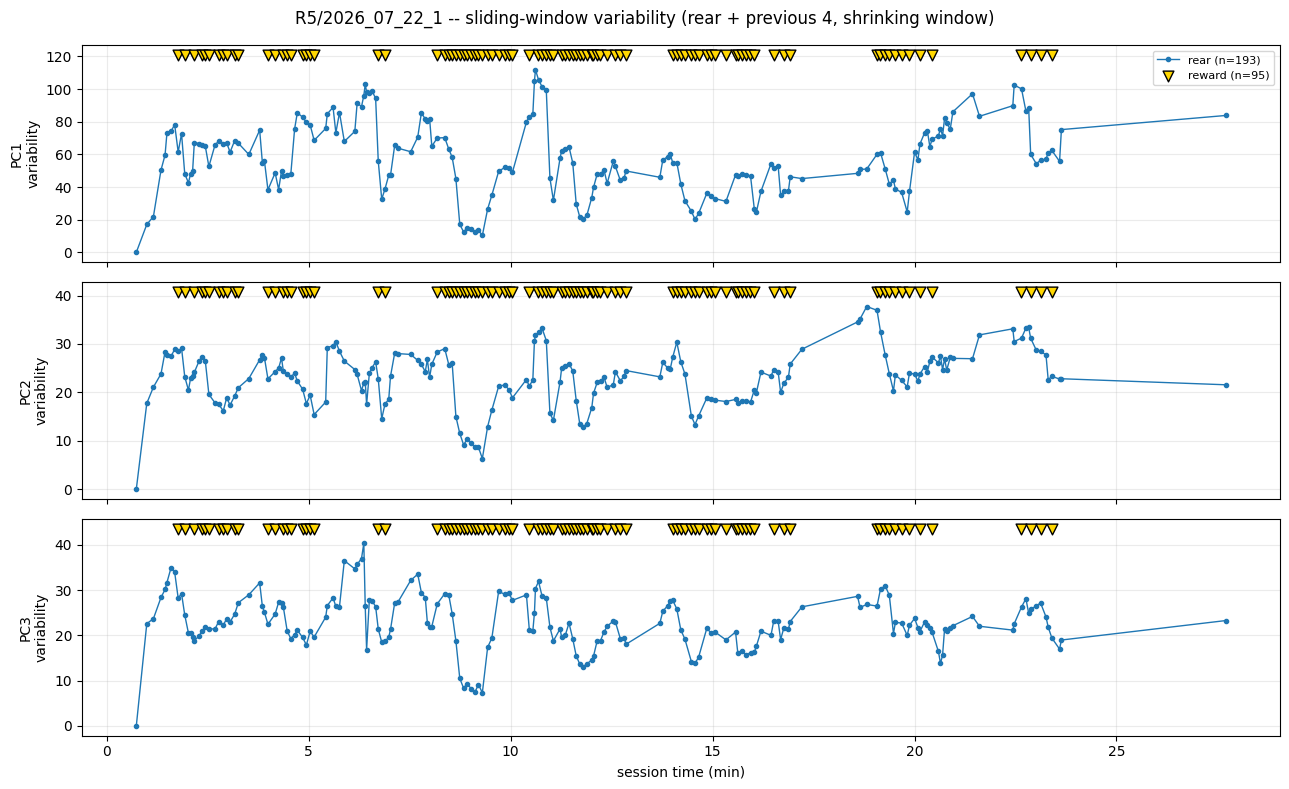

In [8]:
fig, axes = plt.subplots(N_PCS_SHOWN, 1, figsize=(13, 8), sharex=True)
for pidx, ax in enumerate(axes):
    ax.plot(t_rear_min, variability[:, pidx], marker='o', ms=3, lw=1, color='#1f77b4',
            label=f'rear (n={len(t_rear_min)})')
    ytop = variability[:, pidx].max() * 1.08
    ax.scatter(t_reward_min, np.full(len(t_reward_min), ytop), marker='v', s=60,
               color='gold', edgecolor='k', zorder=3, label=f'reward (n={len(t_reward_min)})')
    ax.set_ylabel(f'PC{pidx + 1}\nvariability')
    ax.grid(alpha=0.25)
axes[0].legend(fontsize=8, loc='upper right')
axes[-1].set_xlabel('session time (min)')
fig.suptitle(f'{rat}/{session} -- sliding-window variability '
            f'(rear + previous {LOOKBACK}, shrinking window)')
fig.tight_layout()
plt.show()


## 2. Matched vs unmatched rears -- mean +/- std (4 s / 50 Hz window)

Same comparison as `single_session.ipynb`'s "Matched vs unmatched rears" plot, recomputed
on the new wide native-rate window (+/-2s around the alignment anchor) instead of the
original narrow 1.5s/20Hz template window, so it is directly comparable to the variability
plot above.

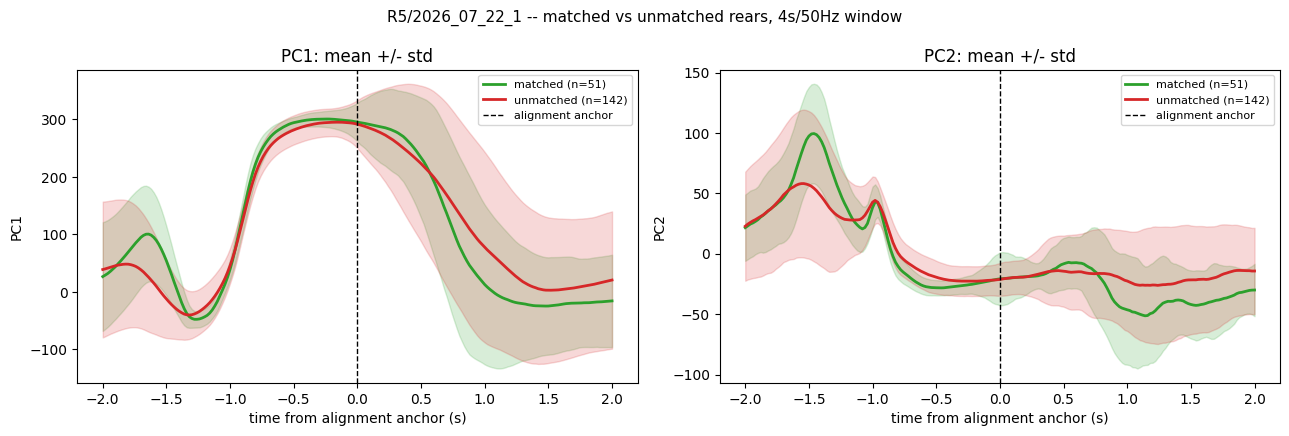

In [9]:
rear_is_matched_valid = rear_is_matched[valid_rear_idx]
t_axis_native_s = (np.arange(2 * HALF_WIN_FRAMES + 1) - HALF_WIN_FRAMES) / DANNCE_FPS

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), sharex=True)
for ax, pidx, label in zip(axes, (0, 1), ('PC1', 'PC2')):
    for mask, color, name in [(rear_is_matched_valid, '#2ca02c', 'matched'),
                                (~rear_is_matched_valid, '#d62728', 'unmatched')]:
        if not mask.any():
            continue
        segs = np.stack([windows[i]['pcs'][:, pidx] for i in np.where(mask)[0]])
        m, s = segs.mean(axis=0), segs.std(axis=0)
        ax.plot(t_axis_native_s, m, lw=2, color=color, label=f'{name} (n={int(mask.sum())})')
        ax.fill_between(t_axis_native_s, m - s, m + s, color=color, alpha=0.18)
    ax.axvline(0, color='k', ls='--', lw=1, label='alignment anchor')
    ax.set_xlabel('time from alignment anchor (s)')
    ax.set_ylabel(label)
    ax.set_title(f'{label}: mean +/- std')
    ax.legend(fontsize=8, loc='best')
fig.suptitle(f'{rat}/{session} -- matched vs unmatched rears, 4s/{DANNCE_FPS:.0f}Hz window',
            fontsize=11)
fig.tight_layout()
plt.show()


## 3. Reward presence vs. absence

"Rewarded" here means the actual online reward event (`behavior_log.csv` `triggered==1`,
already used for the reward markers above) landed within 1s of this rear's alignment
anchor -- i.e. this specific rear is the one the reward was delivered for. This is a
different (and more direct) label than "matched" in section 2: "matched" asks whether an
*offline* replay of the rule on the DANNCE-derived PC stream would also have fired here,
which need not agree with what the real online SLEAP-based rig actually did.

In [10]:
from clirb.native_dannce import label_rears_by_reward

REWARD_TOL_S = 1.0   # tolerance for calling a rear itself "rewarded"
is_rewarded, rears_since_reward, frames_since_reward = label_rears_by_reward(
    anchor_native, reward_frames, tol_frames=int(round(REWARD_TOL_S * DANNCE_FPS)))

print(f'{int(is_rewarded.sum())}/{len(is_rewarded)} rears are rewarded '
      f'(reward within {REWARD_TOL_S:.0f}s of the alignment anchor)')
print(f'{int((rears_since_reward == -1).sum())} rears occurred before any reward this session')


95/193 rears are rewarded (reward within 1s of the alignment anchor)
8 rears occurred before any reward this session


### 3a. Rewarded vs unrewarded rears -- mean +/- std trajectory

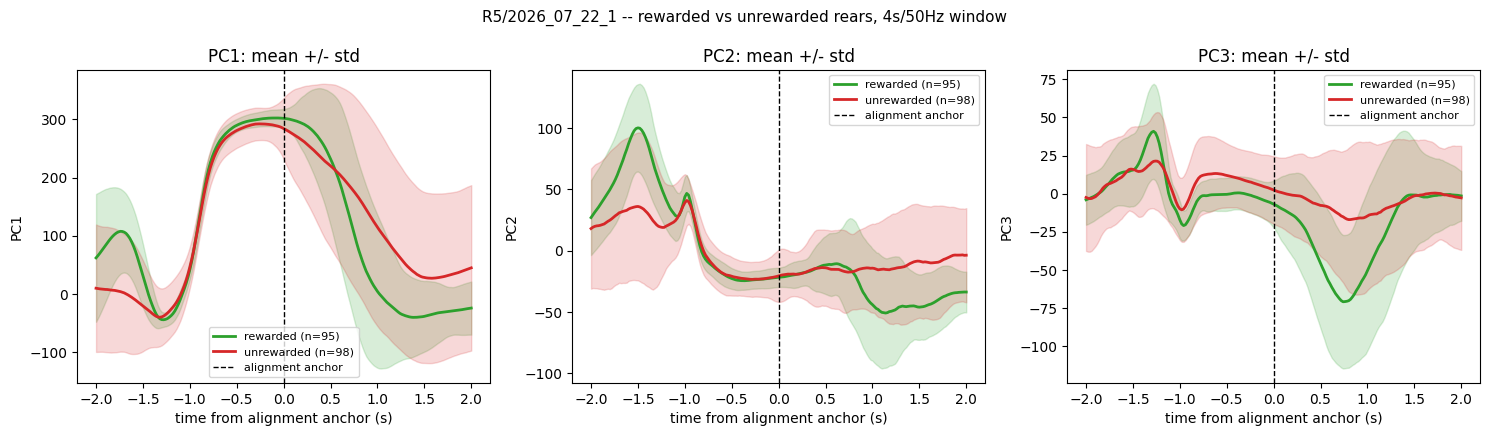

In [11]:
fig, axes = plt.subplots(1, N_PCS_SHOWN, figsize=(15, 4.4), sharex=True)
for ax, pidx, label in zip(axes, range(N_PCS_SHOWN), ('PC1', 'PC2', 'PC3')):
    for mask, color, name in [(is_rewarded, '#2ca02c', 'rewarded'),
                                (~is_rewarded, '#d62728', 'unrewarded')]:
        if not mask.any():
            continue
        segs = np.stack([windows[i]['pcs'][:, pidx] for i in np.where(mask)[0]])
        m, s = segs.mean(axis=0), segs.std(axis=0)
        ax.plot(t_axis_native_s, m, lw=2, color=color, label=f'{name} (n={int(mask.sum())})')
        ax.fill_between(t_axis_native_s, m - s, m + s, color=color, alpha=0.18)
    ax.axvline(0, color='k', ls='--', lw=1, label='alignment anchor')
    ax.set_xlabel('time from alignment anchor (s)')
    ax.set_ylabel(label)
    ax.set_title(f'{label}: mean +/- std')
    ax.legend(fontsize=8, loc='best')
fig.suptitle(f'{rat}/{session} -- rewarded vs unrewarded rears, 4s/{DANNCE_FPS:.0f}Hz window',
            fontsize=11)
fig.tight_layout()
plt.show()


### 3b. Sliding-window variability, rewarded vs unrewarded (scalar comparison)

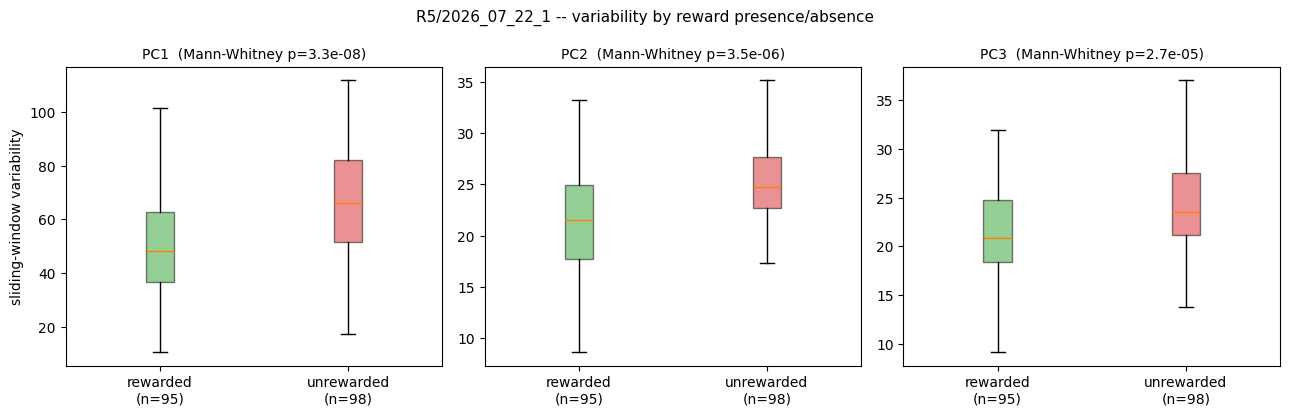

In [12]:
from scipy.stats import mannwhitneyu

fig, axes = plt.subplots(1, N_PCS_SHOWN, figsize=(13, 4.2))
for pidx, ax in enumerate(axes):
    groups = [variability[is_rewarded, pidx], variability[~is_rewarded, pidx]]
    bp = ax.boxplot(groups, tick_labels=[f'rewarded\n(n={int(is_rewarded.sum())})',
                                         f'unrewarded\n(n={int((~is_rewarded).sum())})'],
                    patch_artist=True, showfliers=False)
    for patch, color in zip(bp['boxes'], ['#2ca02c', '#d62728']):
        patch.set_facecolor(color); patch.set_alpha(0.5)
    stat, p = mannwhitneyu(*groups)
    ax.set_title(f'PC{pidx + 1}  (Mann-Whitney p={p:.1e})', fontsize=10)
    if pidx == 0:
        ax.set_ylabel('sliding-window variability')
fig.suptitle(f'{rat}/{session} -- variability by reward presence/absence', fontsize=11)
fig.tight_layout()
plt.show()


### 3c. Does variability recover with time since the last reward?

Restricted to rears that occurred after at least one reward this session (excludes the
warm-up period before the first reward). Bins `rears_since_reward` (0 = the rewarded rear
itself) and shows mean +/- SEM of the sliding-window variability per bin.

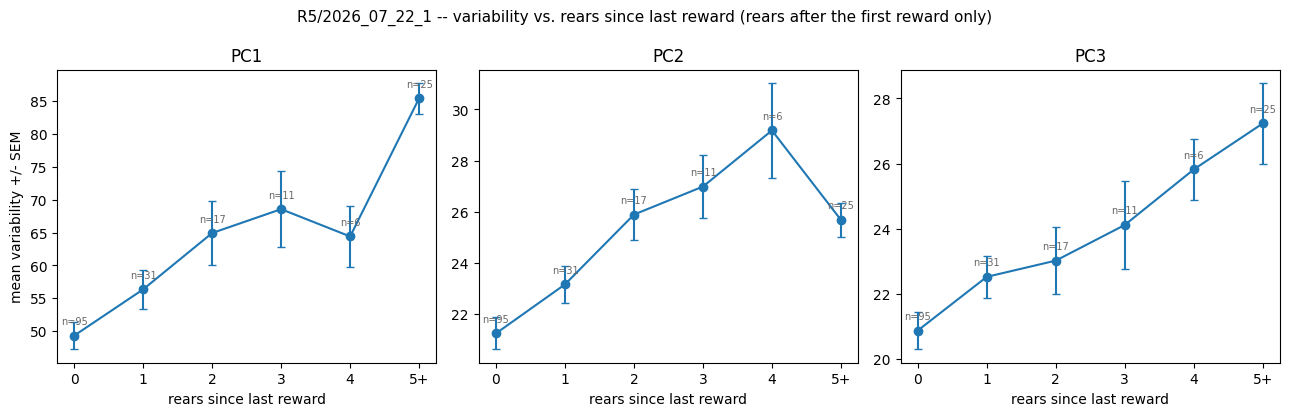

In [13]:
BIN_EDGES = [0, 1, 2, 3, 4, 5, np.inf]
BIN_LABELS = ['0', '1', '2', '3', '4', '5+']

after_reward = rears_since_reward >= 0
bin_idx = np.digitize(rears_since_reward[after_reward], BIN_EDGES[1:-1], right=False)

fig, axes = plt.subplots(1, N_PCS_SHOWN, figsize=(13, 4.2), sharex=True)
for pidx, ax in enumerate(axes):
    means, sems, ns = [], [], []
    for b in range(len(BIN_LABELS)):
        vals = variability[after_reward, pidx][bin_idx == b]
        means.append(vals.mean() if len(vals) else np.nan)
        sems.append(vals.std(ddof=1) / np.sqrt(len(vals)) if len(vals) > 1 else 0.0)
        ns.append(len(vals))
    xs = np.arange(len(BIN_LABELS))
    ax.errorbar(xs, means, yerr=sems, marker='o', color='#1f77b4', capsize=3)
    for x, n, m in zip(xs, ns, means):
        if np.isfinite(m):
            ax.annotate(f'n={n}', (x, m), textcoords='offset points', xytext=(0, 8),
                       fontsize=7, ha='center', color='0.4')
    ax.set_xticks(xs)
    ax.set_xticklabels(BIN_LABELS)
    ax.set_xlabel('rears since last reward')
    ax.set_title(f'PC{pidx + 1}')
    if pidx == 0:
        ax.set_ylabel('mean variability +/- SEM')
fig.suptitle(f'{rat}/{session} -- variability vs. rears since last reward '
            f'(rears after the first reward only)', fontsize=11)
fig.tight_layout()
plt.show()


## 4. Template-like rears: rewarded vs. merely close to the template

Recommendation #2 from the report: separate "rewarded" from "merely template-like". Redo
the offline replay with `bounds_to_use` widened by 1.25x (same `accepted_errors`) -- a more
permissive match than section 2's, and a strict superset of it, since widening the band
only ever admits more windows. Within that broader "close enough to the trained motif"
population, split by the real reward label. If rewarded and unrewarded template-like rears
are equally tight, section 3's effect is really about proximity to the template, not reward
itself; if the split survives here too, reward is doing something beyond what template-
closeness alone explains.

In [14]:
TEMPLATE_LIKE_BOUND_MULT = 1.25

wide_template = dict(template)
wide_template['bounds_to_use'] = template['bounds_to_use'] * TEMPLATE_LIKE_BOUND_MULT
wide_match_frames, _ = replay_rule_offline(pcs_at_sleap, wide_template, accepted_errors=ACCEPTED_ERRORS)
rear_is_template_like, _ = rear_matched(rear_start, rear_end, wide_match_frames, template_len=TEMPLATE_LEN)
is_template_like = rear_is_template_like[valid_rear_idx]

print(f'{int(is_template_like.sum())}/{len(is_template_like)} rears are template-like '
      f'(offline match at {TEMPLATE_LIKE_BOUND_MULT}x bounds), '
      f'vs {int(rear_is_matched_valid.sum())} at standard (1x) bounds')
print(f'  template-like subset -- template-like is a superset of matched: '
      f'{bool(np.all(~rear_is_matched_valid | is_template_like))}')
print(f'  of the template-like rears: {int((is_template_like & is_rewarded).sum())} rewarded, '
      f'{int((is_template_like & ~is_rewarded).sum())} unrewarded')


97/193 rears are template-like (offline match at 1.25x bounds), vs 51 at standard (1x) bounds
  template-like subset -- template-like is a superset of matched: True
  of the template-like rears: 71 rewarded, 26 unrewarded


### 4a. Within template-like rears -- rewarded vs unrewarded, mean +/- std

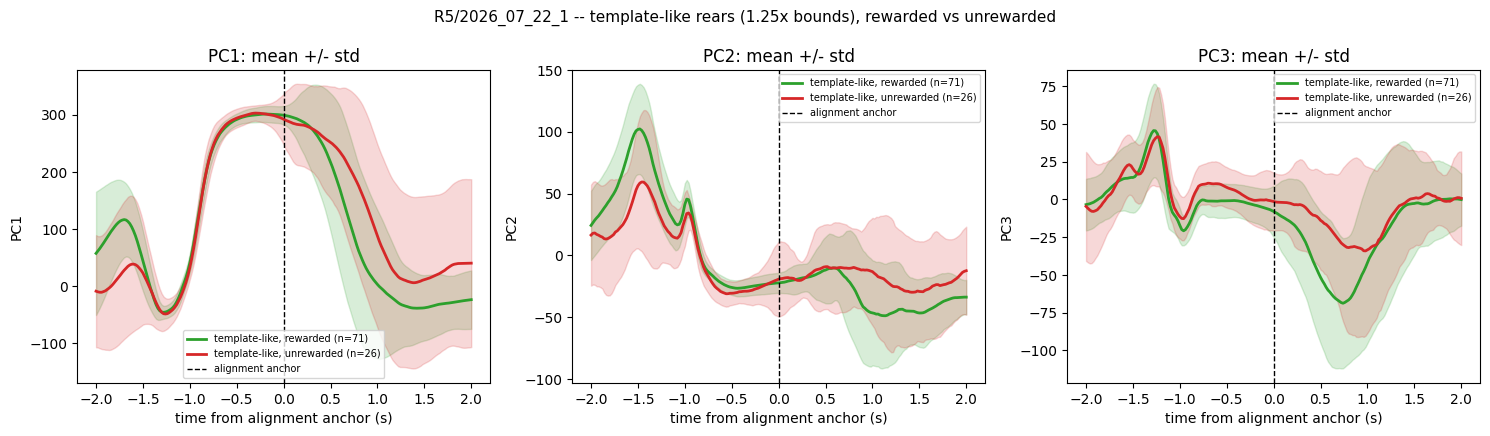

In [15]:
fig, axes = plt.subplots(1, N_PCS_SHOWN, figsize=(15, 4.4), sharex=True)
for ax, pidx, label in zip(axes, range(N_PCS_SHOWN), ('PC1', 'PC2', 'PC3')):
    for mask, color, name in [(is_template_like & is_rewarded, '#2ca02c', 'template-like, rewarded'),
                                (is_template_like & ~is_rewarded, '#d62728', 'template-like, unrewarded')]:
        if not mask.any():
            continue
        segs = np.stack([windows[i]['pcs'][:, pidx] for i in np.where(mask)[0]])
        m, s = segs.mean(axis=0), segs.std(axis=0)
        ax.plot(t_axis_native_s, m, lw=2, color=color, label=f'{name} (n={int(mask.sum())})')
        ax.fill_between(t_axis_native_s, m - s, m + s, color=color, alpha=0.18)
    ax.axvline(0, color='k', ls='--', lw=1, label='alignment anchor')
    ax.set_xlabel('time from alignment anchor (s)')
    ax.set_ylabel(label)
    ax.set_title(f'{label}: mean +/- std')
    ax.legend(fontsize=7, loc='best')
fig.suptitle(f'{rat}/{session} -- template-like rears ({TEMPLATE_LIKE_BOUND_MULT}x bounds), '
            f'rewarded vs unrewarded', fontsize=11)
fig.tight_layout()
plt.show()


### 4b. Within template-like rears -- scalar variability comparison

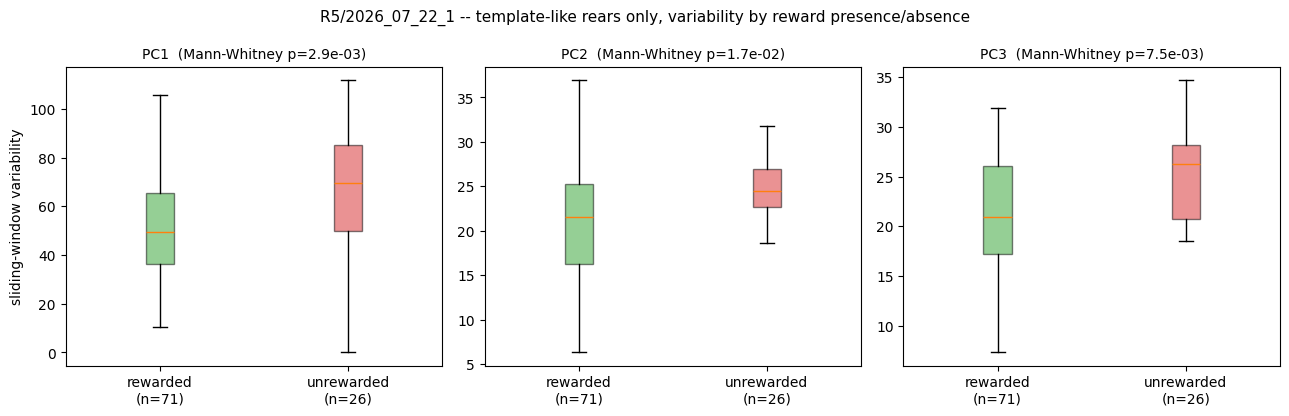

In [16]:
fig, axes = plt.subplots(1, N_PCS_SHOWN, figsize=(13, 4.2))
for pidx, ax in enumerate(axes):
    groups = [variability[is_template_like & is_rewarded, pidx],
             variability[is_template_like & ~is_rewarded, pidx]]
    if min(len(g) for g in groups) < 2:
        ax.set_title(f'PC{pidx + 1} (too few rears in one group)', fontsize=9)
        continue
    bp = ax.boxplot(groups, tick_labels=[f'rewarded\n(n={len(groups[0])})',
                                         f'unrewarded\n(n={len(groups[1])})'],
                    patch_artist=True, showfliers=False)
    for patch, color in zip(bp['boxes'], ['#2ca02c', '#d62728']):
        patch.set_facecolor(color); patch.set_alpha(0.5)
    stat, p = mannwhitneyu(*groups)
    ax.set_title(f'PC{pidx + 1}  (Mann-Whitney p={p:.1e})', fontsize=10)
    if pidx == 0:
        ax.set_ylabel('sliding-window variability')
fig.suptitle(f'{rat}/{session} -- template-like rears only, variability by reward '
            f'presence/absence', fontsize=11)
fig.tight_layout()
plt.show()
